In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [2]:
from google.colab import files

uploaded = files.upload()

Saving usa_housing_kaggle.csv to usa_housing_kaggle.csv


In [4]:
df = pd.read_csv("usa_housing_kaggle.csv")

print(df.head())

    Price  Bedrooms  Bathrooms  SquareFeet  YearBuilt  GarageSpaces  LotSize  \
0  221958         1        1.9        4827       1979             2     1.45   
1  771155         2        2.0        1035       1987             2     1.75   
2  231932         1        3.0        2769       1982             1     1.46   
3  465838         3        3.3        2708       1907             3     1.62   
4  359178         4        3.4        1175       1994             2     0.74   

   ZipCode  CrimeRate  SchoolRating  
0    82240      48.60             5  
1    74315      92.03             9  
2    79249      52.08             3  
3    80587      61.65             1  
4    20756      15.66             4  


In [5]:
print(df.shape)

(300, 10)


In [6]:
print(df.columns)

Index(['Price', 'Bedrooms', 'Bathrooms', 'SquareFeet', 'YearBuilt',
       'GarageSpaces', 'LotSize', 'ZipCode', 'CrimeRate', 'SchoolRating'],
      dtype='object')


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Price         300 non-null    int64  
 1   Bedrooms      300 non-null    int64  
 2   Bathrooms     300 non-null    float64
 3   SquareFeet    300 non-null    int64  
 4   YearBuilt     300 non-null    int64  
 5   GarageSpaces  300 non-null    int64  
 6   LotSize       300 non-null    float64
 7   ZipCode       300 non-null    int64  
 8   CrimeRate     300 non-null    float64
 9   SchoolRating  300 non-null    int64  
dtypes: float64(3), int64(7)
memory usage: 23.6 KB
None


In [8]:
print(df.describe())

               Price    Bedrooms   Bathrooms  SquareFeet    YearBuilt  \
count     300.000000  300.000000  300.000000   300.00000   300.000000   
mean   522761.916667    2.966667    2.464000  3052.75000  1962.616667   
std    256922.348275    1.451175    0.886184  1194.97144    36.005431   
min    112666.000000    1.000000    1.000000   840.00000  1902.000000   
25%    299936.500000    2.000000    1.700000  2053.50000  1931.750000   
50%    505806.500000    3.000000    2.400000  3127.00000  1961.000000   
75%    744603.750000    4.000000    3.200000  4081.00000  1994.000000   
max    999684.000000    5.000000    4.000000  4997.00000  2022.000000   

       GarageSpaces     LotSize       ZipCode   CrimeRate  SchoolRating  
count    300.000000  300.000000    300.000000  300.000000    300.000000  
mean       1.513333    1.062200  54324.770000   49.324033      5.096667  
std        1.116832    0.543896  24718.938552   28.833220      2.674165  
min        0.000000    0.110000  10163.000000 

In [9]:
print(df.isnull().sum())

Price           0
Bedrooms        0
Bathrooms       0
SquareFeet      0
YearBuilt       0
GarageSpaces    0
LotSize         0
ZipCode         0
CrimeRate       0
SchoolRating    0
dtype: int64


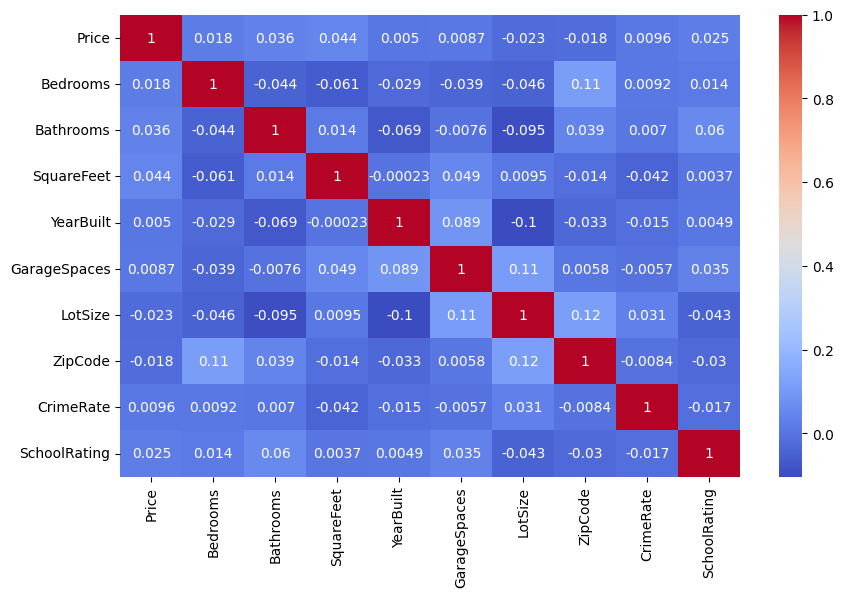

In [10]:
plt.figure(figsize=(10,6))

sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm")

plt.show()

In [12]:
X = df.drop(['Price'], axis=1)

y = df['Price']

print(X.head())
print(y.head())

   Bedrooms  Bathrooms  SquareFeet  YearBuilt  GarageSpaces  LotSize  ZipCode  \
0         1        1.9        4827       1979             2     1.45    82240   
1         2        2.0        1035       1987             2     1.75    74315   
2         1        3.0        2769       1982             1     1.46    79249   
3         3        3.3        2708       1907             3     1.62    80587   
4         4        3.4        1175       1994             2     0.74    20756   

   CrimeRate  SchoolRating  
0      48.60             5  
1      92.03             9  
2      52.08             3  
3      61.65             1  
4      15.66             4  
0    221958
1    771155
2    231932
3    465838
4    359178
Name: Price, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(240, 9)
(60, 9)


In [14]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Trained Successfully")

Model Trained Successfully


In [15]:
print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 729122.8560829684
Bedrooms : 9776.822175545882
Bathrooms : 7912.281121563307
SquareFeet : -2.1563907821071098
YearBuilt : -108.45502542105531
GarageSpaces : 5346.28528761773
LotSize : -9527.93641516563
ZipCode : -0.7042604529124219
CrimeRate : -42.76147246376017
SchoolRating : -1325.0983892311417


In [19]:
small_data = df[['SquareFeet', 'Bedrooms', 'Price']].head(10)

X_small = small_data[['SquareFeet', 'Bedrooms']]

y_small = small_data['Price']

small_model = LinearRegression()

small_model.fit(X_small, y_small)

print("Intercept:", small_model.intercept_)

print("Coefficients:", small_model.coef_)

Intercept: 865192.390412446
Coefficients: [  -104.88018348 -62782.16814541]


In [20]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

        Feature  Coefficient
0      Bedrooms  9776.822176
1     Bathrooms  7912.281122
2    SquareFeet    -2.156391
3     YearBuilt  -108.455025
4  GarageSpaces  5346.285288
5       LotSize -9527.936415
6       ZipCode    -0.704260
7     CrimeRate   -42.761472
8  SchoolRating -1325.098389


In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data)

        Feature       VIF
0      Bedrooms  1.026057
1     Bathrooms  1.025400
2    SquareFeet  1.008049
3     YearBuilt  1.029516
4  GarageSpaces  1.027167
5       LotSize  1.058626
6       ZipCode  1.033922
7     CrimeRate  1.003606
8  SchoolRating  1.008082


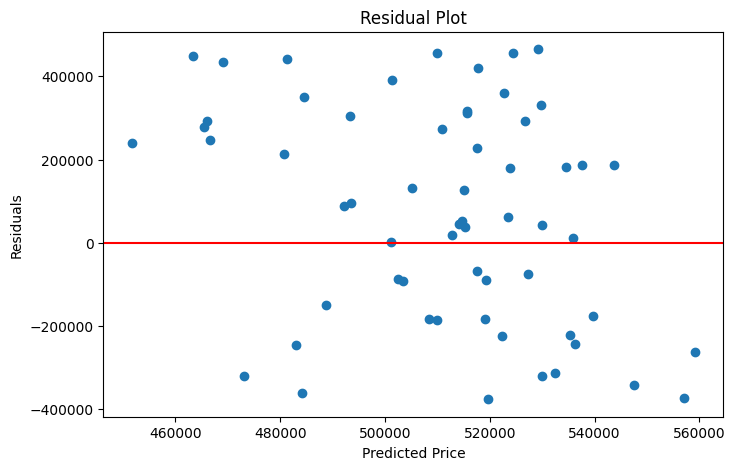

In [22]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color='red')

plt.xlabel("Predicted Price")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

In [23]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

n = X_test.shape[0]

p = X_test.shape[1]

adjusted_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("MAE:", mae)

print("RMSE:", rmse)

print("R2 Score:", r2)

print("Adjusted R2:", adjusted_r2)

MAE: 231698.02918415377
RMSE: 266055.48956836725
R2 Score: -0.13111179800176198
Adjusted R2: -0.3347119216420791


In [24]:
X_single = df[['SquareFeet']]

y_single = df['Price']

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_single, y_single, test_size=0.2, random_state=42
)

single_model = LinearRegression()

single_model.fit(X_train1, y_train1)

single_pred = single_model.predict(X_test1)

print("Single Feature R2:", r2_score(y_test1, single_pred))

print("Multiple Feature R2:", r2_score(y_test, y_pred))

Single Feature R2: -0.08569806951451864
Multiple Feature R2: -0.13111179800176198


In [25]:
new_house = pd.DataFrame([{
    'Bedrooms': 3,
    'Bathrooms': 2,
    'SquareFeet': 2500,
    'YearBuilt': 2010,
    'GarageSpaces': 2,
    'LotSize': 1.5,
    'ZipCode': 82240,
    'CrimeRate': 30,
    'SchoolRating': 7
}])

prediction = model.predict(new_house)

print("Predicted House Price:", prediction[0])

Predicted House Price: 478816.06020758237
